# Sparse-to-Dense on KITTI: detailed evaluation

Analyses a model trained with `colab_train.ipynb`, using its held-out validation drives.

| Section | What it answers |
|---|---|
| 3. Overall metrics | How good is the model compared with a no-learning baseline (and LiDAR-only / camera-only runs, if trained)? |
| 4. Error vs. distance | How does error grow with depth? |
| 5. Error vs. LiDAR coverage | How well does it fill gaps far from any LiDAR point? |
| 6. Per-drive | Is performance consistent across scenes? |
| 7. Best / worst frames | What do successes and failures look like? |
| 8. Where in the image | Which image regions have the largest errors? |
| 9. LiDAR sparsity | How robust is it when fewer LiDAR points are available? |
| 10. Speed | How fast is inference? |
| 11. Test-set submission | (Optional) KITTI-format predictions for the official benchmark |

Takes ~10 min on an L4. Nothing to download besides the dataset: the trained weights are read from Google Drive.
All tables and figures are saved to `<run>/detailed_eval/` on Drive.

## 0. Settings

In [1]:
REPO_URL = 'https://github.com/chauhansrc/kitti-depth-completion.git'
PROJECT_DIR = '/content/kitti-code'
DATA_DIR = '/content/data'
RUNS_DIR = '/content/drive/MyDrive/kitti-runs'

RUN_NAME = 'rgbd_r34'                 # main model to analyse (folder in RUNS_DIR)
ABLATION_RUNS = ['d_r34', 'rgb_r34']  # LiDAR-only / camera-only runs; skipped if not trained yet
LIDAR_KEEP = [1.0, 0.5, 0.25, 0.1]    # fractions of LiDAR points kept in the sparsity test
NUM_EXAMPLES = 3                      # best and worst frames to show
MAKE_TEST_SUBMISSION = False          # True: write KITTI test-set predictions (section 11)
BATCH_SIZE = 8
NUM_WORKERS = 4

CKPT = f'{RUNS_DIR}/{RUN_NAME}/best.pt'
EVAL_DIR = f'{RUNS_DIR}/{RUN_NAME}/detailed_eval'

## 1. Setup

In [2]:
import os, torch
assert torch.cuda.is_available(), 'No GPU: Runtime -> Change runtime type'
print(torch.__version__, '|', torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount('/content/drive')
assert os.path.exists(CKPT), f'No checkpoint at {CKPT}. Train it with colab_train.ipynb first.'
os.makedirs(EVAL_DIR, exist_ok=True)

if os.path.isdir(PROJECT_DIR):
    !git -C {PROJECT_DIR} pull --ff-only
else:
    !git clone {REPO_URL} {PROJECT_DIR}
%cd {PROJECT_DIR}
!git log --oneline -1
!pip install -q -r requirements.txt

2.11.0+cu130 | NVIDIA L4
Mounted at /content/drive
Cloning into '/content/kitti-code'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 20 (delta 2), reused 20 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 15.76 KiB | 15.76 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/kitti-code
e795e7e (HEAD -> main, origin/main, origin/HEAD) README: describe quick-test and auto-resume Colab workflow


## 2. Data and model
Downloads the data only if it isn't already on this runtime.

In [3]:
!bash scripts/download_data.sh {DATA_DIR}

--2026-10-11 17:28:11--  https://s3.eu-central-1.amazonaws.com/avg-kitti/data_depth_selection.zip
Resolving s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)... 52.219.169.21, 52.219.171.249, 3.5.135.138, ...
Connecting to s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)|52.219.169.21|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2010655006 (1.9G) [application/zip]
Saving to: ‘/content/data/data_depth_selection.zip’

/content/data/data_ 100%[===================>]   1.87G  22.0MB/s    in 89s     

2026-10-11 17:29:41 (21.5 MB/s) - ‘/content/data/data_depth_selection.zip’ saved [2010655006/2010655006]

Extracting to /content/data
Done. Frames in val_selection_cropped:
1000


In [7]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from s2d import analysis as A
from s2d.data import KittiDepthSelection
from s2d.vis import save_panel

METRICS = A.METRICS
MODALITY_LABEL = {'rgbd': 'camera + LiDAR', 'd': 'LiDAR only', 'rgb': 'camera only'}
device = torch.device('cuda')

model, ckpt = A.load_checkpoint(CKPT, device)
samples = A.val_samples(ckpt, DATA_DIR)
val_ds = KittiDepthSelection(samples, train=False)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{RUN_NAME}: modality {ckpt['args']['modality']}, ResNet-{ckpt['args']['layers']}, "
      f"{n_params:.1f} M params, best epoch {ckpt['epoch'] + 1}")
print(f"Validation: {len(samples)} frames from {len({s['drive'] for s in samples})} drives")

res = A.predict(model, val_ds, device, BATCH_SIZE, NUM_WORKERS)
nn_pred = A.nearest_fill_all(res['sparse'])
frames = A.per_frame_table(res['pred'], res['gt'], res['names'])
frames_nn = A.per_frame_table(nn_pred, res['gt'], res['names'])
print('Predictions:', res['pred'].shape)

rgbd_r34: modality rgbd, ResNet-34, 26.1 M params, best epoch 29
Validation: 291 frames from 4 drives


predict:   0%|          | 0/37 [00:00<?, ?it/s]

Predictions: (291, 352, 1216)


## 3. Overall metrics
KITTI-style: each metric is computed per frame, then averaged. RMSE/MAE in mm, iRMSE/iMAE in 1/km, δ<1.25 is the
fraction of pixels within 25% of the true depth.

**Nearest-neighbour fill** gives every pixel the depth of the closest LiDAR point. It uses no learning and no camera,
so it shows how much the network adds over simple interpolation.

In [8]:
rows = {
    f"{RUN_NAME} ({MODALITY_LABEL[ckpt['args']['modality']]})": frames[METRICS].mean(),
    'nearest-neighbour fill (no learning)': frames_nn[METRICS].mean(),
}
for run in ABLATION_RUNS:
    path = f'{RUNS_DIR}/{run}/best.pt'
    if not os.path.exists(path):
        print(f'Skipping {run}: not trained yet (train it in colab_train.ipynb with MODALITY set accordingly)')
        continue
    m2, c2 = A.load_checkpoint(path, device)
    if set(c2['val_names']) != set(ckpt['val_names']):
        print(f'Skipping {run}: validated on a different split, so not comparable')
        continue
    r2 = A.predict(m2, val_ds, device, BATCH_SIZE, NUM_WORKERS)
    rows[f"{run} ({MODALITY_LABEL[c2['args']['modality']]})"] = \
        A.per_frame_table(r2['pred'], r2['gt'], r2['names'])[METRICS].mean()
    del m2, r2

overall = pd.DataFrame(rows).T
overall.to_csv(f'{EVAL_DIR}/overall.csv')
overall.round({'rmse': 1, 'mae': 1, 'irmse': 2, 'imae': 2, 'delta1': 4})

Skipping d_r34: not trained yet (train it in colab_train.ipynb with MODALITY set accordingly)
Skipping rgb_r34: not trained yet (train it in colab_train.ipynb with MODALITY set accordingly)


,rmse,mae,irmse,imae,delta1
rgbd_r34 (camera + LiDAR),1961.4,1095.1,21.50,8.72,0.9378
nearest-neighbour fill (no learning),2273.2,462.7,6.29,1.77,0.9835


## 4. Error vs. distance
GT pixels from all frames pooled and grouped by true depth. Depth errors naturally grow with distance:
LiDAR points get sparser and each pixel covers more of the scene.

In [9]:
edges = [0, 10, 20, 30, 40, 50, 60, 70, np.inf]
d_model = A.binned_errors(res['pred'], res['gt'], res['gt'], edges, 'depth_m')
d_nn = A.binned_errors(nn_pred, res['gt'], res['gt'], edges, 'depth_m')
by_depth = d_model.merge(d_nn[['depth_m', 'rmse', 'mae']], on='depth_m', suffixes=('', '_nn'))
by_depth.to_csv(f'{EVAL_DIR}/by_depth.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(by_depth))
axes[0].plot(x, by_depth['rmse'], marker='o', label='model')
axes[0].plot(x, by_depth['rmse_nn'], marker='o', label='nearest-neighbour fill')
axes[0].set_ylabel('RMSE (mm)'); axes[0].legend()
axes[1].bar(x, by_depth['pixels_%'], color='C7'); axes[1].set_ylabel('% of GT pixels')
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(by_depth['depth_m']); ax.set_xlabel('true depth (m)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/by_depth.png', dpi=100); plt.show()
by_depth.round(1)

,depth_m,pixels_%,rmse,mae,rmse_nn,mae_nn
0,0-10,41.7,1295.4,781.7,1595.4,214.7
1,10-20,36.3,1538.5,941.2,2255.2,398.9
2,20-30,9.9,2244.5,1377.0,2759.9,712.1
3,30-40,5.4,2963.7,1855.5,3009.1,979.4
4,40-50,3.1,3616.7,2266.3,3408.7,1266.0
5,50-60,2.0,4049.1,2522.1,3801.2,1349.4
6,60-70,1.2,4753.0,2876.5,4553.4,1408.0
7,70-inf,0.4,7815.8,4563.5,8712.3,3249.5


## 5. Error vs. LiDAR coverage
Groups GT pixels by their distance (in pixels) to the nearest LiDAR point. Distance 0 means a LiDAR point sits on
that pixel. Large distances are gaps the model must fill from the image and its surroundings.

In [10]:
dist = np.stack([A.lidar_distance(s) for s in res['sparse']])
edges = [0, 1, 2, 4, 8, 16, 32, np.inf]
c_model = A.binned_errors(res['pred'], res['gt'], dist, edges, 'px_to_lidar')
c_nn = A.binned_errors(nn_pred, res['gt'], dist, edges, 'px_to_lidar')
by_cov = c_model.merge(c_nn[['px_to_lidar', 'rmse', 'mae']], on='px_to_lidar', suffixes=('', '_nn'))
by_cov.to_csv(f'{EVAL_DIR}/by_lidar_distance.csv', index=False)
del dist

x = np.arange(len(by_cov))
plt.figure(figsize=(8, 4))
plt.plot(x, by_cov['mae'], marker='o', label='model')
plt.plot(x, by_cov['mae_nn'], marker='o', label='nearest-neighbour fill')
plt.xticks(x, by_cov['px_to_lidar']); plt.xlabel('distance to nearest LiDAR point (px)'); plt.ylabel('MAE (mm)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/by_lidar_distance.png', dpi=100); plt.show()
by_cov.round(1)

,px_to_lidar,pixels_%,rmse,mae,rmse_nn,mae_nn
0,0-1,14.7,1877.1,1054.4,1972.3,220.8
1,1-2,45.7,2004.1,1143.7,2539.8,512.9
2,2-4,36.8,1767.2,985.2,1941.3,438.5
3,4-8,2.6,2612.9,1212.6,3415.0,764.3
4,8-16,0.2,6381.3,3445.9,8979.9,3340.1
5,16-32,0.0,13357.0,7012.1,12954.6,6162.0
6,32-inf,0.0,43628.5,31854.6,17551.9,11762.7


## 6. Per-drive results
Each validation drive is a different scene (city, residential, road, campus).

In [11]:
by_drive = frames.groupby('drive')[METRICS].mean()
by_drive.insert(0, 'frames', frames.groupby('drive').size())
by_drive['rmse_nn'] = frames_nn.groupby('drive')['rmse'].mean()
by_drive.to_csv(f'{EVAL_DIR}/by_drive.csv')
by_drive.round({'rmse': 1, 'mae': 1, 'irmse': 2, 'imae': 2, 'delta1': 4, 'rmse_nn': 1})

,frames,rmse,mae,irmse,imae,delta1,rmse_nn
drive,,,,,,,
2011_09_26_drive_0005_sync,48,2017.1,1137.0,20.50,8.29,0.9325,2061.7
2011_09_26_drive_0036_sync,203,1921.0,1074.4,20.96,8.56,0.9426,2246.0
2011_09_28_drive_0037_sync,20,2451.1,1325.6,31.15,11.60,0.8959,2944.2
2011_09_29_drive_0026_sync,20,1747.9,974.7,19.65,8.57,0.9437,2386.2


## 7. Per-frame distribution, best and worst frames

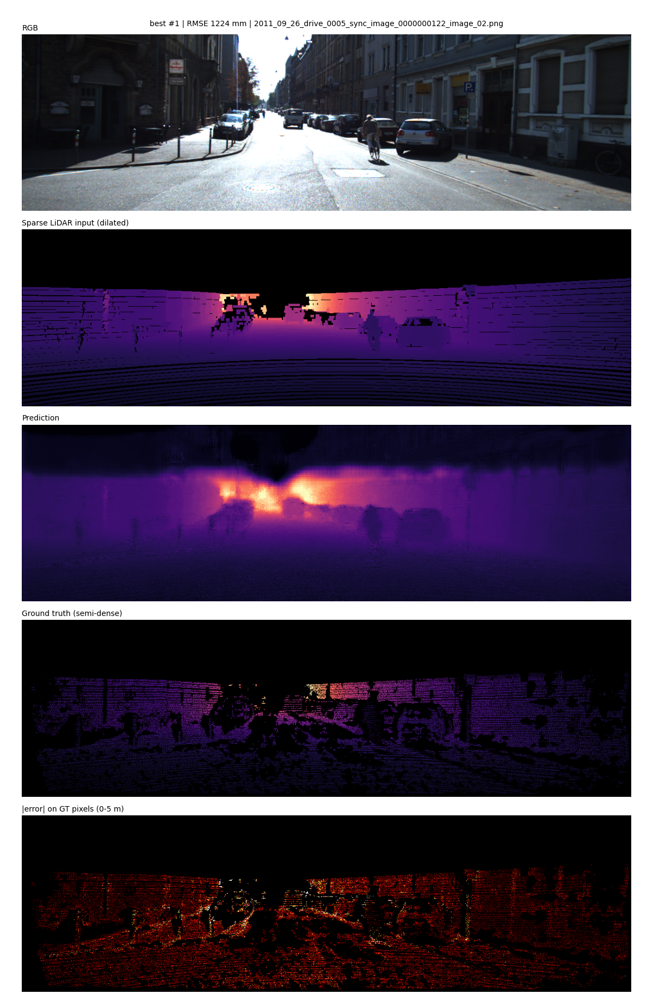

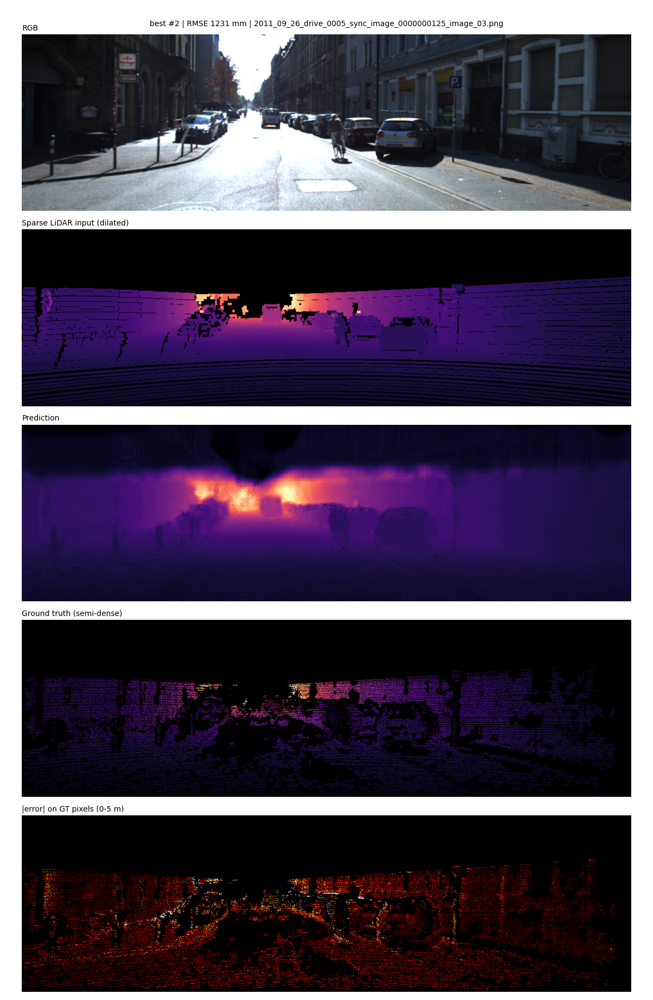

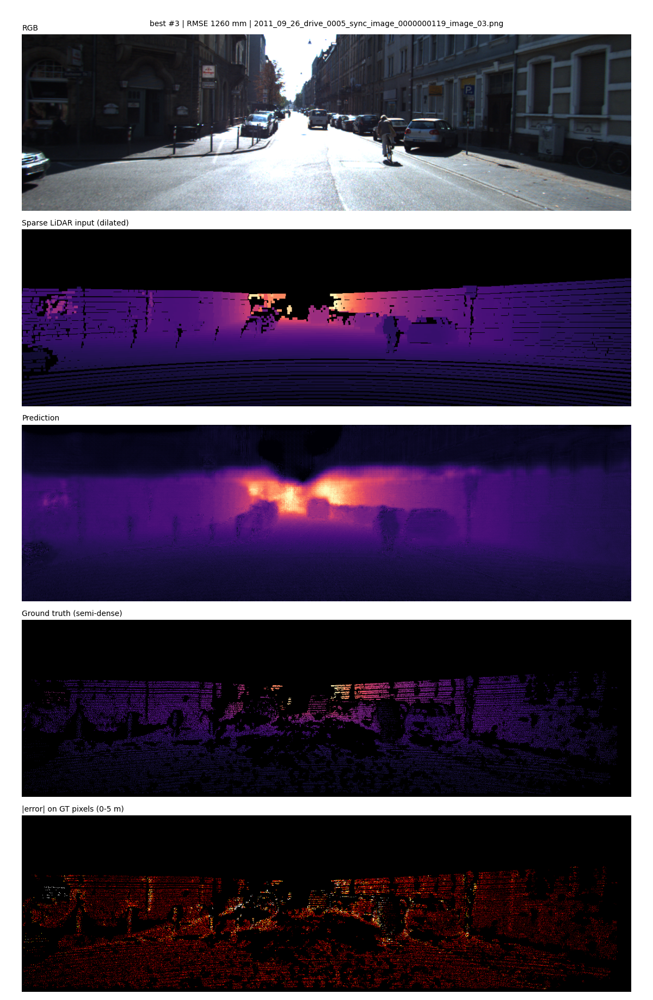

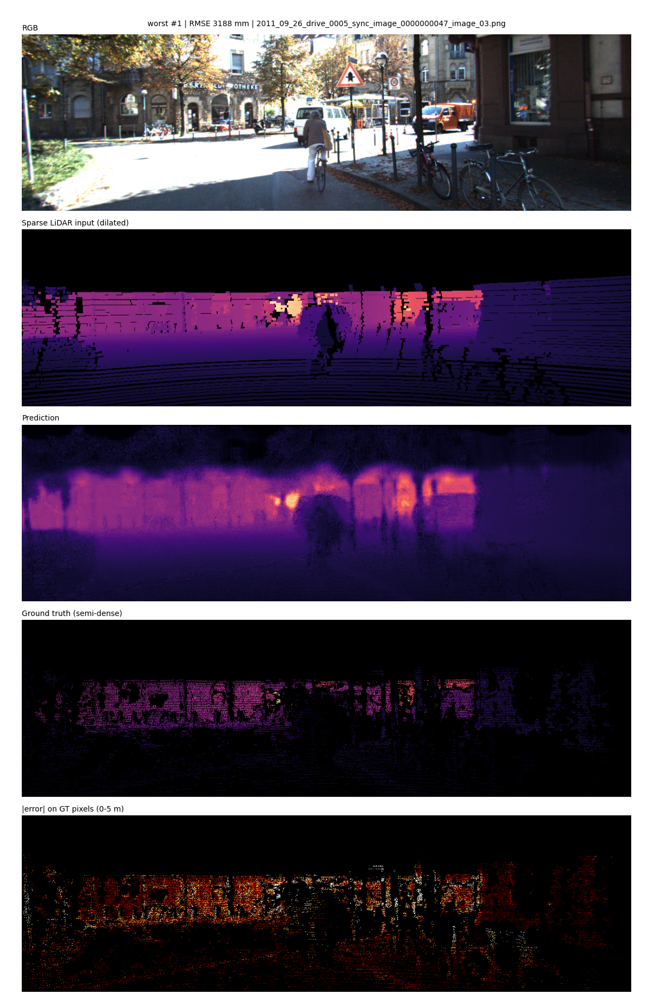

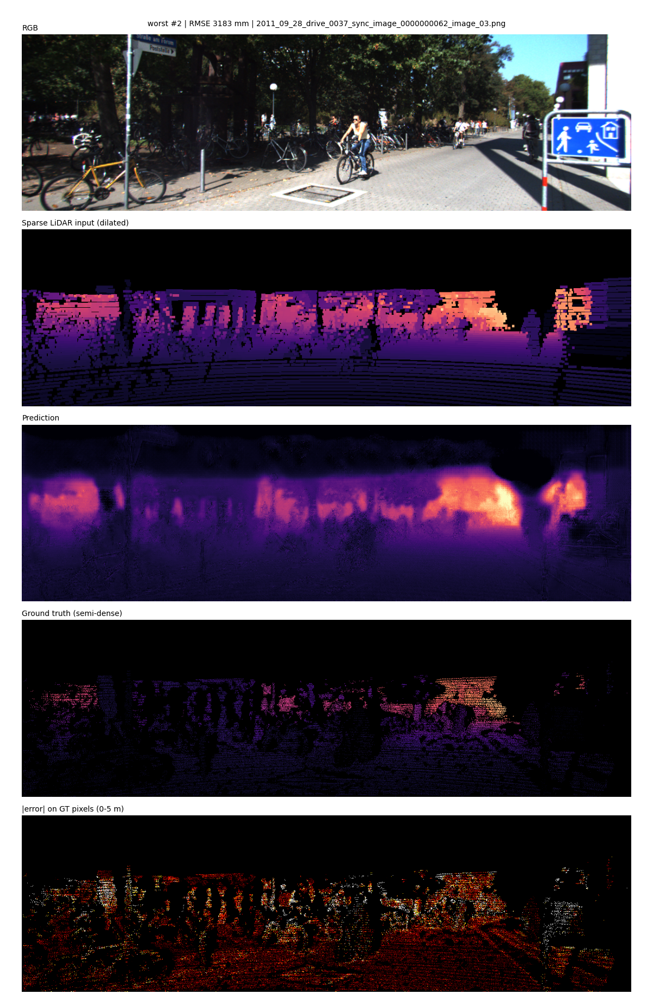

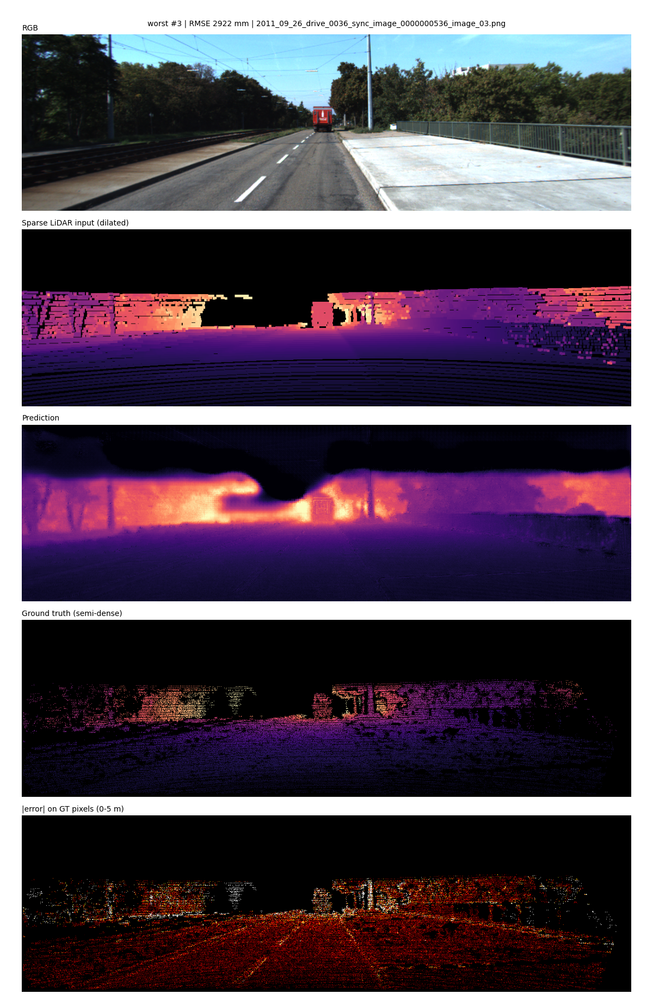

In [12]:
plt.figure(figsize=(8, 3.5))
bins = np.linspace(0, max(frames['rmse'].max(), frames_nn['rmse'].max()), 40)
plt.hist(frames_nn['rmse'], bins=bins, alpha=0.6, label='nearest-neighbour fill')
plt.hist(frames['rmse'], bins=bins, alpha=0.6, label='model')
plt.xlabel('per-frame RMSE (mm)'); plt.ylabel('frames'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/rmse_hist.png', dpi=100); plt.show()

ordered = frames.sort_values('rmse')
for label, subset in [('best', ordered.head(NUM_EXAMPLES)), ('worst', ordered.tail(NUM_EXAMPLES)[::-1])]:
    for rank, row in enumerate(subset.itertuples(), 1):
        item = val_ds[row.idx]
        path = f'{EVAL_DIR}/{label}{rank}_{row.name}'
        save_panel(path, item['rgb'], item['sparse'], torch.from_numpy(res['pred'][row.idx])[None], item['gt'],
                   title=f'{label} #{rank} | RMSE {row.rmse:.0f} mm | {row.name}')
        display(Image(filename=path))

## 8. Where in the image are errors largest?
Left: mean absolute error at each pixel position across all validation frames (white = never has GT).
Right: error per image row. The top rows lie above the LiDAR's field of view.

In [13]:
mae_map, count = A.spatial_mae(res['pred'], res['gt'])
rows_model = A.row_mae(res['pred'], res['gt'])
rows_nn = A.row_mae(nn_pred, res['gt'])

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={'width_ratios': [3, 1]})
im = axes[0].imshow(mae_map, cmap='hot', vmin=0, vmax=np.nanpercentile(mae_map, 99))
axes[0].set_title('mean |error| per pixel (m)'); axes[0].axis('off')
plt.colorbar(im, ax=axes[0], fraction=0.015)
axes[1].plot(rows_model, np.arange(len(rows_model)), label='model')
axes[1].plot(rows_nn, np.arange(len(rows_nn)), label='NN fill')
axes[1].invert_yaxis(); axes[1].set_xlabel('MAE (m)'); axes[1].set_ylabel('image row'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/spatial_error.png', dpi=100); plt.show()

## 9. Robustness to LiDAR sparsity
Randomly removes LiDAR points at test time, simulating a cheaper sensor or dropouts. The model was trained only
with full-density LiDAR, so some degradation is expected. Compare how quickly each method degrades.

In [14]:
sparsity = []
for keep in LIDAR_KEEP:
    r = A.predict(model, A.LidarSubsample(val_ds, keep), device, BATCH_SIZE, NUM_WORKERS)
    m = A.per_frame_table(r['pred'], r['gt'], r['names'])[METRICS].mean()
    n = A.per_frame_table(A.nearest_fill_all(r['sparse']), r['gt'], r['names'])[METRICS].mean()
    sparsity.append({'lidar_kept': keep, 'lidar_px_%': 100 * (r['sparse'] > 0).mean(),
                     'rmse': m['rmse'], 'mae': m['mae'], 'rmse_nn': n['rmse'], 'mae_nn': n['mae']})
    print(f"keep {keep:.0%}: model RMSE {m['rmse']:.0f} mm | NN fill RMSE {n['rmse']:.0f} mm")
    del r
sparsity = pd.DataFrame(sparsity)
sparsity.to_csv(f'{EVAL_DIR}/lidar_sparsity.csv', index=False)

plt.figure(figsize=(8, 4))
plt.plot(sparsity['lidar_kept'] * 100, sparsity['rmse'], marker='o', label='model')
plt.plot(sparsity['lidar_kept'] * 100, sparsity['rmse_nn'], marker='o', label='nearest-neighbour fill')
cam = [k for k in overall.index if 'camera only' in k]
if cam:
    plt.axhline(overall.loc[cam[0], 'rmse'], color='C2', ls='--', label='camera-only model')
plt.gca().invert_xaxis(); plt.xlabel('% of LiDAR points kept'); plt.ylabel('RMSE (mm)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(f'{EVAL_DIR}/lidar_sparsity.png', dpi=100); plt.show()
sparsity.round(1)

predict:   0%|          | 0/37 [00:00<?, ?it/s]

keep 100%: model RMSE 1961 mm | NN fill RMSE 2273 mm


predict:   0%|          | 0/37 [00:00<?, ?it/s]

keep 50%: model RMSE 2590 mm | NN fill RMSE 2547 mm


predict:   0%|          | 0/37 [00:00<?, ?it/s]

keep 25%: model RMSE 3725 mm | NN fill RMSE 2845 mm


predict:   0%|          | 0/37 [00:00<?, ?it/s]

keep 10%: model RMSE 5453 mm | NN fill RMSE 3394 mm


,lidar_kept,lidar_px_%,rmse,mae,rmse_nn,mae_nn
0,1.0,4.3,1961.4,1095.1,2273.2,462.7
1,0.5,2.2,2589.7,1651.3,2546.6,561.1
2,0.2,1.1,3725.5,2637.1,2845.2,706.1
3,0.1,0.4,5453.0,4132.6,3394.0,990.8


## 10. Inference speed
Full 352×1216 frames, mixed precision.

In [15]:
speed = pd.DataFrame([A.benchmark(model, device, batch_size=b) for b in (1, 8)])
speed.insert(0, 'gpu', torch.cuda.get_device_name(0))
speed.to_csv(f'{EVAL_DIR}/speed.csv', index=False)
speed.round(1)

,gpu,batch_size,ms_per_batch,frames_per_s,peak_gpu_mem_mb
0,NVIDIA L4,1,52.2,19.1,730.7
1,NVIDIA L4,8,481.6,16.6,4767.0
